In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
print("Library berhasil diimpor.")


Library berhasil diimpor.


In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    csv_candidates = [name for name in uploaded if name.lower().endswith(".csv")]
    if csv_candidates:
        df = pd.read_csv(csv_candidates[0])
    else:
        raise FileNotFoundError("CSV tidak dipilih.")
except Exception as e:
    print("CSV belum diunggah atau notebook berjalan di luar Colab.")
    print("Membuat dataset sintetis untuk latihan.")
    rng = np.random.default_rng(SEED)
    n = 500
    dates = pd.date_range("2025-01-01", periods=n, freq="D")
    building = rng.choice(["Gedung Kuliah A", "Gedung Kuliah B", "Laboratorium", "Perpustakaan"], n)
    area = np.clip(rng.normal(125, 45, n), 50, 300).round(1)
    weekend = (dates.dayofweek >= 5).astype(int)
    hours = np.where(weekend == 1, rng.uniform(0, 4, n), rng.uniform(4, 12, n)).round(1)
    users = np.where(weekend == 1, rng.integers(0, 50, n), rng.integers(20, 220, n))
    temp = rng.normal(30, 2.3, n).clip(24, 36).round(1)
    ac = np.clip(hours*rng.uniform(.45, 1, n) + (temp-28)*.25, 0, 14).round(1)
    base = pd.Series(building).map({"Gedung Kuliah A":12,"Gedung Kuliah B":10,"Laboratorium":14,"Perpustakaan":20}).to_numpy()
    energy = np.clip(base + area*.045 + users*.055 + ac*3.2 + hours*1.4 + np.maximum(temp-28,0)*1.6 + rng.normal(0,4.5,n), 5, None).round(2)
    df = pd.DataFrame({
        "tanggal": dates.strftime("%Y-%m-%d"), "gedung": building,
        "luas_m2": area, "jumlah_pengguna": users, "suhu_c": temp,
        "jam_operasional": hours, "jam_ac": ac, "akhir_pekan": weekend,
        "energi_kwh": energy
    })

df.head()


CSV belum diunggah atau notebook berjalan di luar Colab.
Membuat dataset sintetis untuk latihan.


,tanggal,gedung,luas_m2,jumlah_pengguna,suhu_c,jam_operasional,jam_ac,akhir_pekan,energi_kwh
0,2025-01-01,Gedung Kuliah A,120.8,171,28.2,7.0,4.6,0,56.27
1,2025-01-02,Perpustakaan,50.0,41,30.2,7.2,4.6,0,50.36
2,2025-01-03,Laboratorium,59.0,102,28.2,8.7,7.3,0,58.31
3,2025-01-04,Gedung Kuliah B,220.8,31,27.5,0.0,0.0,1,21.36
4,2025-01-05,Gedung Kuliah B,67.1,20,30.5,3.4,3.2,1,36.29


In [3]:
print("Ukuran dataset:", df.shape)
display(df.head())
print("\\nTipe data:")
print(df.dtypes)
print("\\nNilai kosong per kolom:")
print(df.isna().sum())
print("\\nJumlah baris duplikat:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df = df.dropna(subset=["energi_kwh"]).copy()
df["tanggal"] = pd.to_datetime(df["tanggal"], errors="coerce")
df = df.dropna(subset=["tanggal"])
print("Ukuran setelah pembersihan:", df.shape)


Ukuran dataset: (500, 9)


,tanggal,gedung,luas_m2,jumlah_pengguna,suhu_c,jam_operasional,jam_ac,akhir_pekan,energi_kwh
0,2025-01-01,Gedung Kuliah A,120.8,171,28.2,7.0,4.6,0,56.27
1,2025-01-02,Perpustakaan,50.0,41,30.2,7.2,4.6,0,50.36
2,2025-01-03,Laboratorium,59.0,102,28.2,8.7,7.3,0,58.31
3,2025-01-04,Gedung Kuliah B,220.8,31,27.5,0.0,0.0,1,21.36
4,2025-01-05,Gedung Kuliah B,67.1,20,30.5,3.4,3.2,1,36.29


\nTipe data:
tanggal             object
gedung              object
luas_m2            float64
jumlah_pengguna      int64
suhu_c             float64
jam_operasional    float64
jam_ac             float64
akhir_pekan          int64
energi_kwh         float64
dtype: object
\nNilai kosong per kolom:
tanggal            0
gedung             0
luas_m2            0
jumlah_pengguna    0
suhu_c             0
jam_operasional    0
jam_ac             0
akhir_pekan        0
energi_kwh         0
dtype: int64
\nJumlah baris duplikat: 0
Ukuran setelah pembersihan: (500, 9)


,luas_m2,jumlah_pengguna,suhu_c,jam_operasional,jam_ac,energi_kwh
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,124.14,90.78,30.07,6.41,5.09,53.63
std,43.70,65.68,2.38,3.45,2.81,17.31
min,50.00,0.00,24.00,0.00,0.00,13.34
25%,91.40,32.00,28.50,3.60,3.00,40.46
50%,124.30,79.00,30.10,6.55,4.80,54.53
75%,152.48,146.00,31.80,9.33,7.10,66.50
max,255.70,219.00,36.00,12.00,12.30,97.61


,rata_rata_kwh
gedung,
Perpustakaan,59.20
Gedung Kuliah A,53.22
Laboratorium,52.88
Gedung Kuliah B,49.48


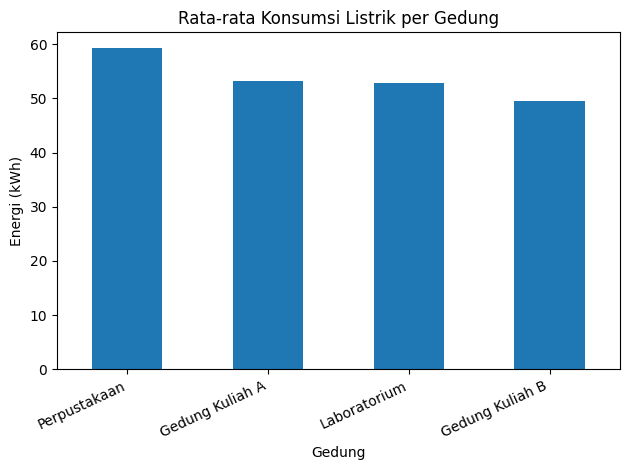

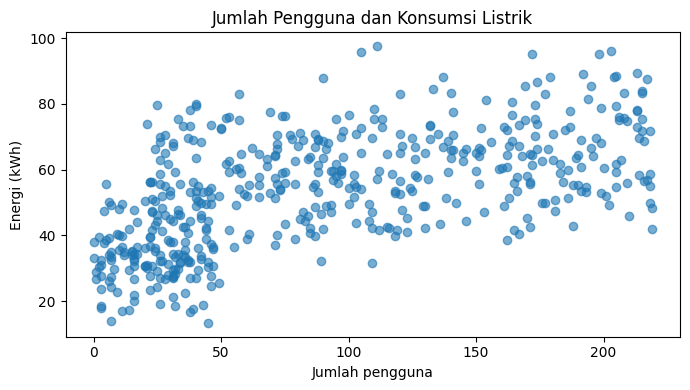

In [4]:
display(df[["luas_m2","jumlah_pengguna","suhu_c","jam_operasional","jam_ac","energi_kwh"]].describe().round(2))
rata_gedung = df.groupby("gedung")["energi_kwh"].mean().sort_values(ascending=False)
display(rata_gedung.rename("rata_rata_kwh").round(2))

rata_gedung.plot(kind="bar")
plt.title("Rata-rata Konsumsi Listrik per Gedung")
plt.xlabel("Gedung")
plt.ylabel("Energi (kWh)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(df["jumlah_pengguna"], df["energi_kwh"], alpha=0.6)
plt.title("Jumlah Pengguna dan Konsumsi Listrik")
plt.xlabel("Jumlah pengguna")
plt.ylabel("Energi (kWh)")
plt.tight_layout()
plt.show()


In [5]:
feature_cols = [
    "gedung", "luas_m2", "jumlah_pengguna", "suhu_c",
    "jam_operasional", "jam_ac", "akhir_pekan"
]
target_col = "energi_kwh"

X = df[feature_cols].copy()
y = df[target_col].astype(float)

categorical = ["gedung"]
numeric = [c for c in feature_cols if c not in categorical]

preprocessor = ColumnTransformer(
    transformers=[
        ("kategori", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("angka", "passthrough", numeric)
    ]
)

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=SEED))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Model selesai dilatih.")
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))


Model selesai dilatih.
Jumlah data latih: 400
Jumlah data uji: 100


MAE : 4.73 kWh
RMSE: 5.63 kWh
R²  : 0.868


,aktual_kwh,prediksi_kwh
0,38.04,29.36
1,36.85,33.10
2,27.77,24.10
3,42.31,46.78
4,55.60,55.80
5,59.52,66.76
6,79.47,76.30
7,41.58,46.18
8,50.44,47.05
9,60.15,60.57


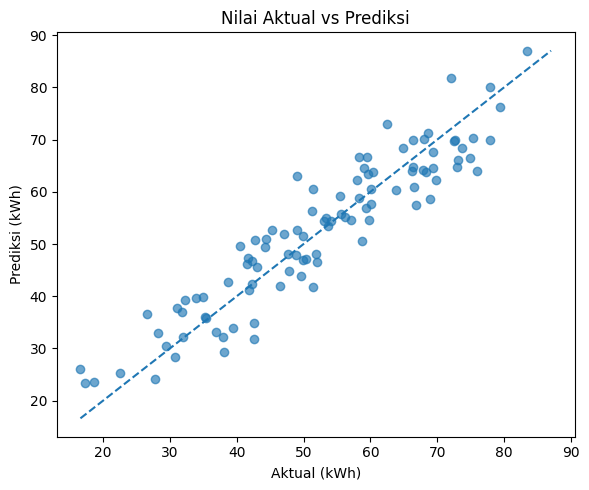

In [6]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE : {mae:.2f} kWh")
print(f"RMSE: {rmse:.2f} kWh")
print(f"R²  : {r2:.3f}")

comparison = pd.DataFrame({
    "aktual_kwh": y_test.to_numpy(),
    "prediksi_kwh": predictions.round(2)
})
display(comparison.head(10))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, predictions, alpha=0.65)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Nilai Aktual vs Prediksi")
plt.xlabel("Aktual (kWh)")
plt.ylabel("Prediksi (kWh)")
plt.tight_layout()
plt.show()


In [7]:
contoh = pd.DataFrame([{
    "gedung": "Gedung Kuliah A",
    "luas_m2": 120,
    "jumlah_pengguna": 100,
    "suhu_c": 31,
    "jam_operasional": 8,
    "jam_ac": 6,
    "akhir_pekan": 0
}])

hasil = model.predict(contoh)[0]
print(f"Perkiraan konsumsi listrik: {hasil:.2f} kWh per hari")


Perkiraan konsumsi listrik: 60.55 kWh per hari
